# Xây dựng mô hình Naive Bayes trên dữ liệu hành vi khách hàng

Dữ liệu: `Customer_Behaviour.csv` trong cùng thư mục. Dự đoán `Purchased` (0: không mua, 1: mua) từ tuổi và thu nhập ước tính bằng GaussianNB của Scikit-learn.

Luồng thực hiện: đọc dữ liệu → chọn đặc trưng → chia train/test → điền median và chuẩn hóa → huấn luyện → dự đoán và đánh giá.

Tham khảo giải thuật: [Naive Bayes trong Scikit-learn](https://scikit-learn.org/stable/modules/naive_bayes.html).


## 0. Import thư viện


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline


## 1. Chuẩn bị dữ liệu


In [2]:
df = pd.read_csv('Customer_Behaviour.csv')
print("Kích thước dữ liệu:", df.shape)
print(df.head().to_string(index=False))
print("\nSố lượng mẫu mỗi lớp:")
print(df['Purchased'].value_counts().sort_index())
print("\nSố dòng trùng lặp:", df.duplicated().sum())


Kích thước dữ liệu: (400, 5)
 User ID Gender  Age  EstimatedSalary  Purchased
15624510   Male   19            19000          0
15810944   Male   35            20000          0
15668575 Female   26            43000          0
15603246 Female   27            57000          0
15804002   Male   19            76000          0

Số lượng mẫu mỗi lớp:
Purchased
0    257
1    143
Name: count, dtype: int64

Số dòng trùng lặp: 0


### 1.1. Chọn đặc trưng và nhãn

Chọn `Age` và `EstimatedSalary` để xây dựng Gaussian Naive Bayes trên hai đặc trưng số. Loại `User ID` vì đây là mã định danh. `Gender` là đặc trưng phân loại và chưa được sử dụng trong mô hình cơ sở này. `Purchased` chỉ làm nhãn dự đoán.

Không áp dụng quy tắc đổi số 0 thành NaN của dữ liệu diabetes cho bộ dữ liệu này.


In [3]:
X = df[["Age", "EstimatedSalary"]]
y = df["Purchased"]
print("Kiểu dữ liệu đặc trưng:")
print(X.dtypes)
print("\nGiá trị thiếu:")
print(X.isna().sum())


Kiểu dữ liệu đặc trưng:
Age                int64
EstimatedSalary    int64
dtype: object

Giá trị thiếu:
Age                0
EstimatedSalary    0
dtype: int64


### 1.2. Chia dữ liệu theo 80/20 với random_state là 42


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print("Kích thước train/test:", X_train.shape, X_test.shape)
print("Tỉ lệ lớp (train):")
print(y_train.value_counts(normalize=True))
print("\nGiá trị thiếu (train):")
print(X_train.isna().sum())


Kích thước train/test: (320, 2) (80, 2)
Tỉ lệ lớp (train):
Purchased
0    0.64375
1    0.35625
Name: proportion, dtype: float64

Giá trị thiếu (train):
Age                0
EstimatedSalary    0
dtype: int64


### 1.3. Cấu hình điền giá trị thiếu bằng median

Dữ liệu hiện tại không có giá trị thiếu. Đặt SimpleImputer trong Pipeline để thống nhất luồng xử lý. Median chỉ được học từ train khi gọi `model.fit`, không học từ test.


In [5]:
imputer = SimpleImputer(strategy="median")


## 2. Tiền xử lý và huấn luyện Naive Bayes

Pipeline gồm điền median, chuẩn hóa và GaussianNB. GaussianNB không bắt buộc chuẩn hóa; ở đây dùng StandardScaler để đưa tuổi và thu nhập về cùng thang đo, đồng thời giảm ảnh hưởng chênh lệch thang đo lên thành phần ổn định số học `var_smoothing`.

GaussianNB giả định phân phối chuẩn của từng đặc trưng trong mỗi lớp. StandardScaler không biến dữ liệu thành phân phối chuẩn. Mọi tham số tiền xử lý chỉ được học trên train.


In [6]:
from sklearn.preprocessing import StandardScaler
from sklearn.naive_bayes import GaussianNB

model = Pipeline([
    ("imputer", imputer),
    ("scaler", StandardScaler()),
    ("nb", GaussianNB())
])
model.fit(X_train, y_train)
print("Đã huấn luyện Gaussian Naive Bayes.")


Đã huấn luyện Gaussian Naive Bayes.


## 3. Dự đoán và đánh giá mô hình


Accuracy trên train: 0.8875
Accuracy trên test: 0.875

Báo cáo phân loại:
              precision    recall  f1-score   support

   Không mua     0.8868    0.9216    0.9038        51
         Mua     0.8519    0.7931    0.8214        29

    accuracy                         0.8750        80
   macro avg     0.8693    0.8573    0.8626        80
weighted avg     0.8741    0.8750    0.8740        80



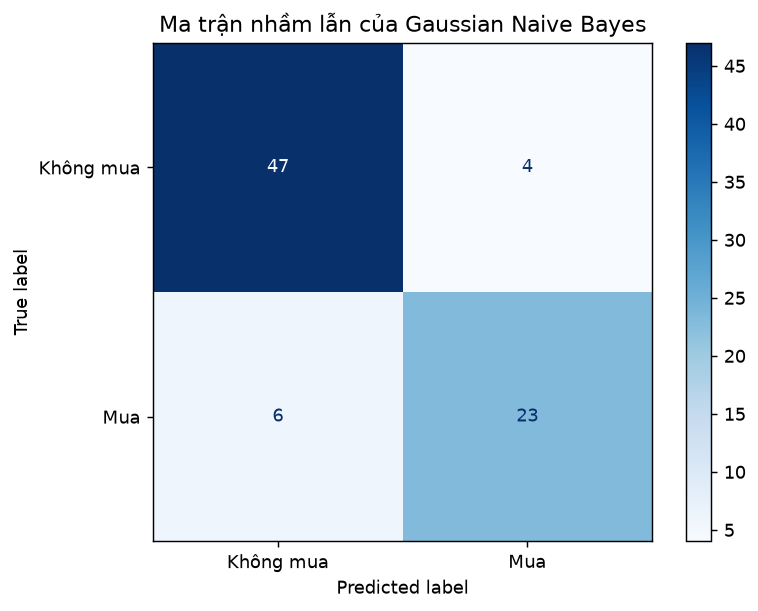

In [7]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

y_pred = model.predict(X_test)
print("Accuracy trên train:", model.score(X_train, y_train))
print("Accuracy trên test:", accuracy_score(y_test, y_pred))
print("\nBáo cáo phân loại:")
print(classification_report(
    y_test, y_pred,
    labels=[0, 1],
    target_names=['Không mua', 'Mua'],
    digits=4,
    zero_division=0
))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred,
    labels=[0, 1],
    display_labels=['Không mua', 'Mua'],
    cmap="Blues"
)
plt.title("Ma trận nhầm lẫn của Gaussian Naive Bayes")
plt.tight_layout()
plt.show()


## 4. Nhận xét

- **Độ chính xác:** Accuracy train đạt **88,75%**, test đạt **87,50%**, tương ứng dự đoán đúng **70/80 mẫu test**.
- **Kết quả lớp mua:** Precision đạt **85,19%**, recall đạt **79,31%**, F1-score đạt **82,14%**; nhận diện đúng **23/29 mẫu** thuộc lớp này.
- **Ma trận nhầm lẫn:** Có **47 mẫu không mua được dự đoán đúng**, **4 mẫu không mua bị dự đoán thành mua**, **6 mẫu mua bị dự đoán thành không mua** và **23 mẫu mua được dự đoán đúng**.
- **Chênh lệch train/test:** Accuracy train cao hơn test **1.25 điểm phần trăm**. Một lần chia dữ liệu chưa đủ để khẳng định mô hình có hoặc không overfitting.

**Kết luận:** Gaussian Naive Bayes đã hoàn thành luồng dự đoán hành vi mua hàng từ tuổi và thu nhập. Đây là mô hình cơ sở trên hai đặc trưng số, chưa sử dụng giới tính. Giả định phân phối chuẩn trong từng lớp và độc lập có điều kiện là các giới hạn cần lưu ý khi diễn giải kết quả.